<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/KMeansCosine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## K-Means Cosine — Spherical K-Means (K-Means Cosine)
Bagian dari 9 konfigurasi (3 algoritma x 3 metrik). Dataset PBL: properti_multi_kota.csv. k=3 (fair comparison).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics.pairwise import cosine_distances
import time
import tracemalloc
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
print("Library siap.")

Library siap.


In [2]:
df = pd.read_csv('properti_multi_kota.csv')
print("Shape awal:", df.shape)
df.head()

Shape awal: (64650, 8)


,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08


In [3]:
# ============================================
# PREPROCESSING UNIVERSAL - dataset baru
# ============================================

# 1. Hapus duplikat (hasil scraping dari banyak sumber)
before = len(df)
df = df.drop_duplicates()
print(f"[1] Hapus duplikat       : {before} -> {len(df)}")

# 2. Hapus outlier & nilai tidak wajar (error scraping)
before = len(df)
df = df[(df['luas_m2'] >= 10) & (df['luas_m2'] <= 2000)]
df = df[(df['luas_bangunan'].isna()) |
        ((df['luas_bangunan'] >= 10) & (df['luas_bangunan'] <= 2000))]
df = df[(df['harga'] >= 50_000_000) & (df['harga'] <= 100_000_000_000)]
df = df[df['jumlah_kamar'].isna() | (df['jumlah_kamar'] <= 20)]
df = df[df['jumlah_kamar_mandi'].isna() | (df['jumlah_kamar_mandi'] <= 20)]
print(f"[2] Hapus outlier        : {before} -> {len(df)}")

# 3. Perbaiki usia_bangunan: sebagian sumber menyimpan TAHUN bangunan
#    (misal 2020), bukan usia. Nilai > 100 dikonversi: usia = 2026 - tahun.
mask_tahun = df['usia_bangunan'] > 100
df.loc[mask_tahun, 'usia_bangunan'] = 2026 - df.loc[mask_tahun, 'usia_bangunan']
df.loc[~df['usia_bangunan'].between(0, 100) & df['usia_bangunan'].notna(),
       'usia_bangunan'] = np.nan
print(f"[3] Konversi tahun->usia : {mask_tahun.sum()} baris dikonversi")

# 4. Isi missing values dengan median
FEATURES = ['luas_m2', 'luas_bangunan', 'jumlah_kamar',
            'jumlah_kamar_mandi', 'usia_bangunan', 'harga']
for col in FEATURES:
    df[col] = df[col].fillna(df[col].median())
print(f"[4] Missing values diisi : {df[FEATURES].isnull().sum().sum()} tersisa")

# 5. Sampling 15.000 data (reproducible) - dataset asli ~56 ribu,
#    sampling agar Hierarchical & DBSCAN layak dijalankan.
df = df.sample(n=15000, random_state=42).reset_index(drop=True)
print(f"[5] Sampling             : 15.000 data (random_state=42)")

# 6. Scaling (StandardScaler untuk euclidean/manhattan)
X = df[FEATURES].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Khusus cosine: L2 normalization (setiap vektor jadi unit vector)
X_cosine = normalize(X_scaled, norm='l2')

print(f"[6] Data siap clustering : {X_scaled.shape}")
print(f"[7] Fitur                : {FEATURES}")

[1] Hapus duplikat       : 64650 -> 57494
[2] Hapus outlier        : 57494 -> 56170
[3] Konversi tahun->usia : 2757 baris dikonversi
[4] Missing values diisi : 0 tersisa
[5] Sampling             : 15.000 data (random_state=42)
[6] Data siap clustering : (15000, 6)
[7] Fitur                : ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'usia_bangunan', 'harga']


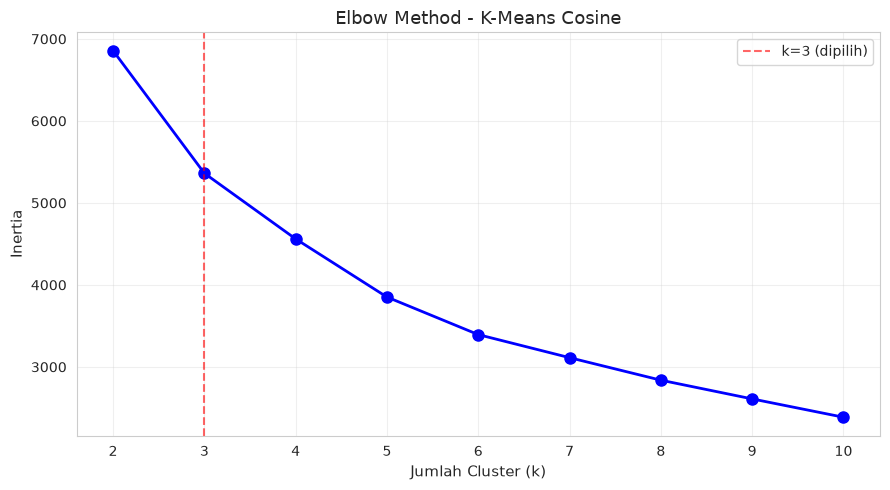

Nilai inertia per k:
  k=2: 6856.56
  k=3: 5361.35
  k=4: 4560.49
  k=5: 3851.60
  k=6: 3393.56
  k=7: 3112.37
  k=8: 2837.79
  k=9: 2609.46
  k=10: 2386.00


In [4]:
# Coba k = 2 sampai 10
K_RANGE = range(2, 11)
inertia = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cosine)
    inertia.append(km.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(K_RANGE, inertia, 'bo-', linewidth=2, markersize=8)
plt.axvline(x=3, color='red', linestyle='--', alpha=0.6, label='k=3 (dipilih)')
plt.xlabel('Jumlah Cluster (k)', fontsize=11); plt.ylabel('Inertia', fontsize=11)
plt.title('Elbow Method - K-Means Cosine', fontsize=13)
plt.xticks(K_RANGE); plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

print("Nilai inertia per k:")
for k, i in zip(K_RANGE, inertia):
    print(f"  k={k}: {i:.2f}")

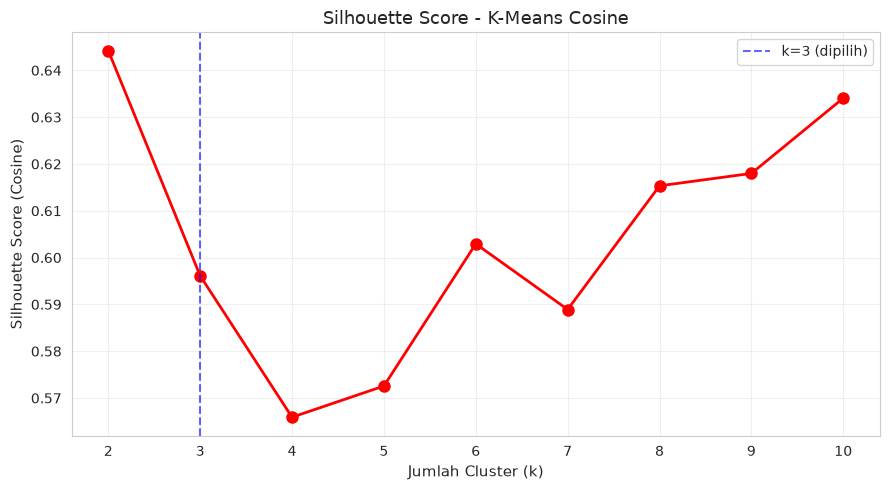

Silhouette Score per k:
  k=2: 0.6442
  k=3: 0.5961
  k=4: 0.5659
  k=5: 0.5726
  k=6: 0.6029
  k=7: 0.5889
  k=8: 0.6153
  k=9: 0.6180
  k=10: 0.6341

>> Silhouette tertinggi: k=2.
>> Tetap dipakai k=3 agar SAMA di semua metode (fair comparison).


In [5]:
sil_scores = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_tmp = km.fit_predict(X_cosine)
    sil_scores.append(silhouette_score(X_cosine, labels_tmp, metric='cosine'))

plt.figure(figsize=(9, 5))
plt.plot(K_RANGE, sil_scores, 'ro-', linewidth=2, markersize=8)
plt.axvline(x=3, color='blue', linestyle='--', alpha=0.6, label='k=3 (dipilih)')
plt.xlabel('Jumlah Cluster (k)', fontsize=11)
plt.ylabel('Silhouette Score (Cosine)', fontsize=11)
plt.title('Silhouette Score - K-Means Cosine', fontsize=13)
plt.xticks(K_RANGE); plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

print("Silhouette Score per k:")
for k, s in zip(K_RANGE, sil_scores):
    print(f"  k={k}: {s:.4f}")
print(f"\n>> Silhouette tertinggi: k={list(K_RANGE)[np.argmax(sil_scores)]}.")
print(">> Tetap dipakai k=3 agar SAMA di semua metode (fair comparison).")

In [6]:
# ============================================
# SPHERICAL K-MEANS (K-Means untuk metrik Cosine)
# Data sudah L2-normalized (unit vector). Setiap iterasi centroid
# dihitung dari rata-rata anggota lalu di-normalize ulang ke unit vector.
# ============================================
K_OPTIMAL = 3  # sama di semua metode (fair comparison)

def spherical_kmeans(X, k, random_state=42, max_iter=100):
    rng = np.random.RandomState(random_state)
    centroids = X[rng.choice(len(X), k, replace=False)].copy()
    centroids = normalize(centroids, norm='l2')
    for it in range(max_iter):
        sim = X @ centroids.T          # cosine similarity (data unit-norm)
        lab = sim.argmax(axis=1)
        new = np.array([normalize(X[lab == j].mean(axis=0).reshape(1, -1),
                                  norm='l2')[0] if (lab == j).any()
                        else centroids[j] for j in range(k)])
        if np.allclose(new, centroids):
            break
        centroids = new
    return lab, centroids, it + 1

tracemalloc.start()
start = time.time()
labels, centroids, n_iter = spherical_kmeans(X_cosine, K_OPTIMAL)
exec_time = time.time() - start
_, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()

df['cluster'] = labels
# centroid untuk visualisasi (inverse transform ke skala asli)
class _M: pass
kmeans = _M(); kmeans.cluster_centers_ = centroids  # untuk scatter plot

print("="*55); print("HASIL SPHERICAL K-MEANS (COSINE)"); print("="*55)
print(f"Jumlah cluster : {K_OPTIMAL}")
print(f"Iterasi konvergen: {n_iter}")
print(f"Waktu eksekusi : {exec_time*1000:.2f} ms")
print(f"Peak memory    : {peak/1024:.2f} KB")
print("\nDistribusi cluster:")
print(df['cluster'].value_counts().sort_index())

HASIL SPHERICAL K-MEANS (COSINE)
Jumlah cluster : 3
Iterasi konvergen: 11
Waktu eksekusi : 27.22 ms
Peak memory    : 930.70 KB

Distribusi cluster:
cluster
0    7723
1    2487
2    4790
Name: count, dtype: int64


In [7]:
print("Rata-rata fitur per cluster:")
print(df.groupby('cluster')[FEATURES].mean().round(2))

Rata-rata fitur per cluster:
         luas_m2  luas_bangunan  jumlah_kamar  jumlah_kamar_mandi  \
cluster                                                             
0          96.01          51.09          2.25                1.18   
1         104.20          84.37          1.29                1.69   
2         303.29         228.28          4.13                3.22   

         usia_bangunan         harga  
cluster                               
0                 9.81  5.683457e+08  
1                10.93  1.115327e+09  
2                10.71  3.542130e+09  


In [8]:
print("\nDistribusi lokasi per cluster (10 lokasi terbanyak):")
top_lokasi = df['lokasi'].value_counts().head(10).index
print(pd.crosstab(df['cluster'], df.loc[df['lokasi'].isin(top_lokasi), 'lokasi']))

print("\nDistribusi sumber data per cluster (10 sumber terbanyak):")
top_sumber = df['sumber'].value_counts().head(10).index
print(pd.crosstab(df['cluster'], df.loc[df['sumber'].isin(top_sumber), 'sumber']))


Distribusi lokasi per cluster (10 lokasi terbanyak):
lokasi   Bekasi  Depok  Kabupaten Bandung  Kabupaten Bekasi  Kabupaten Bogor  \
cluster                                                                        
0           235    150                286               304              409   
1           104     87                 90               108               74   
2           158    150                 36                47               45   

lokasi   Kabupaten Sidoarjo  Kabupaten Tangerang  Semarang  Surabaya  \
cluster                                                                
0                       318                  224       182       145   
1                        65                  104        56        41   
2                        48                  125       114       254   

lokasi   Tangerang Selatan  
cluster                     
0                      132  
1                      109  
2                      195  

Distribusi sumber data per cluster (10

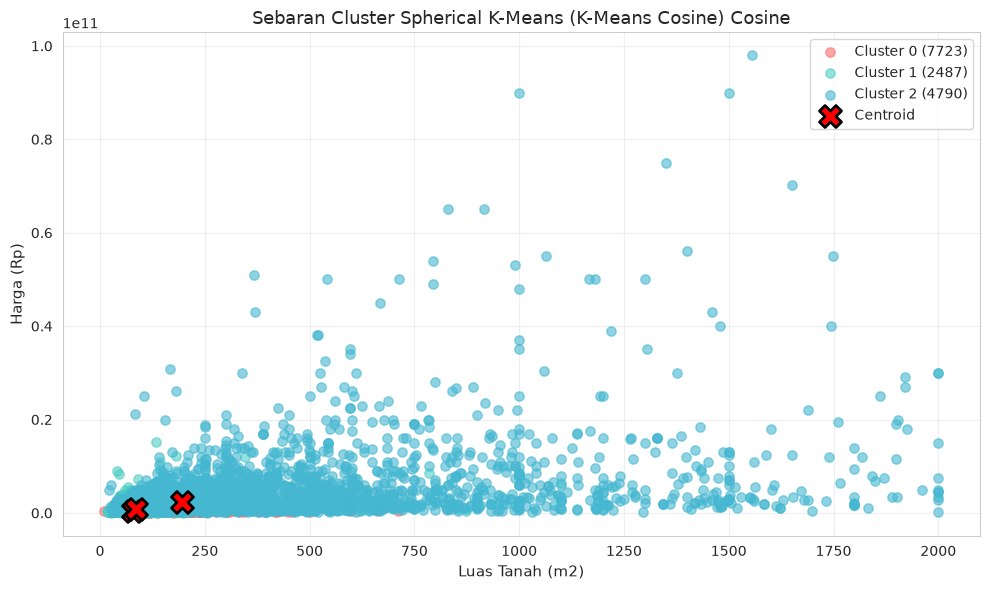

In [9]:
plt.figure(figsize=(10, 6))
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7',
          '#DDA0DD', '#F0E68C', '#87CEEB', '#FFB6C1']
for i, label in enumerate(sorted(df['cluster'].unique())):
    subset = df[df['cluster'] == label]
    plt.scatter(subset['luas_m2'], subset['harga'], s=45, alpha=0.6,
                c=colors[i % len(colors)], label=f'Cluster {label} ({len(subset)})')

centroids_orig = scaler.inverse_transform(kmeans.cluster_centers_)
idx_luas, idx_harga = FEATURES.index('luas_m2'), FEATURES.index('harga')
plt.scatter(centroids_orig[:, idx_luas], centroids_orig[:, idx_harga],
            c='red', marker='X', s=250, edgecolor='black', linewidth=2,
            label='Centroid', zorder=5)
plt.xlabel('Luas Tanah (m2)', fontsize=11)
plt.ylabel('Harga (Rp)', fontsize=11)
plt.title('Sebaran Cluster Spherical K-Means (K-Means Cosine) Cosine', fontsize=13)
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

In [10]:
# ============================================
# EVALUASI (sesuai outline UTS)
# ============================================
# Silhouette dengan metrik yang sama dengan clustering
sil_final = silhouette_score(X_cosine, df['cluster'], metric='cosine')
# DBI selalu dihitung dengan Euclidean (sesuai outline)
dbi_final = davies_bouldin_score(X_scaled, df['cluster'])

print(f"Silhouette Score (Cosine) : {sil_final:.4f}  (makin besar makin bagus)")
print(f"Davies-Bouldin Index (Euclidean): {dbi_final:.4f}  (makin kecil makin bagus)")
print(f"ARI / NMI : -  (dataset tidak memiliki label ground truth)")

Silhouette Score (Cosine) : 0.4784  (makin besar makin bagus)
Davies-Bouldin Index (Euclidean): 1.7610  (makin kecil makin bagus)
ARI / NMI : -  (dataset tidak memiliki label ground truth)


In [11]:
hasil = {
    'Metode'              : 'Spherical K-Means (K-Means Cosine)',
    'Distance Metric'     : 'Cosine',
    'Jumlah Cluster'      : K_OPTIMAL,
    'Jumlah Noise'        : 0,
    '% Noise'             : 0.0,
    'Waktu Eksekusi (ms)' : round(exec_time * 1000, 2),
    'Silhouette'          : round(sil_final, 4),
    'DBI (Euclidean)'     : round(dbi_final, 4),
    'ARI'                 : '-',
    'NMI'                 : '-',
    'Parameter'           : 'k=3 (spherical)'
}

tabel = pd.DataFrame([hasil])
print("="*60)
print("RINGKASAN METRIK - SPHERICAL K-MEANS (K-MEANS COSINE) COSINE")
print("="*60)
tabel.T

RINGKASAN METRIK - SPHERICAL K-MEANS (K-MEANS COSINE) COSINE


,0
Metode,Spherical K-Means (K-Means Cosine)
Distance Metric,Cosine
Jumlah Cluster,3
Jumlah Noise,0
% Noise,0.0
Waktu Eksekusi (ms),27.22
Silhouette,0.4784
DBI (Euclidean),1.761
ARI,-
NMI,-
